# 05 — Bandwidth of every local memory level of the H100 NVL: shared memory, L1, L2 and HBM

**Goal.** How many bytes per cycle can one SM move from its shared memory and from its L1 cache, and how many terabytes per second can the whole GPU move from the L2 cache and from HBM, using ordinary load and store instructions?

These are the ceilings against which every later bandwidth measurement on this GPU is read, in particular the ones for distributed shared memory and for the asynchronous copy engine. Two complications shape the experiment:
- The L2 is split into two partitions, and a line read from the other partition is copied into the reader's own. "L2 bandwidth" therefore depends on where the data lives, and the far case can only be seen on a line's first read.
- At each level the attainable rate depends on how many bytes are in flight. Every level is therefore swept over threads, independent accesses per thread and active SMs, not measured at a single point.

## Background

**Bandwidth and bytes in flight.** A load stays outstanding for its latency *L*. To sustain a rate *B*, *B · L* bytes must be in flight (Little's law). At a few hundred cycles of L2 or HBM latency, one SM needs tens of KiB outstanding. A thread therefore issues several *independent* loads (instruction-level parallelism, ILP) before it uses any of the data, and many threads (warps) do this at once.

In the kernels here:
- one *step* of a thread is ILP independent loads, issued back to back;
- the step's data is then consumed (XORed into an accumulator), so a thread never has more than ILP loads outstanding.

**Shared memory and L1.**
- Both live in one 256 KiB SRAM per SM. The driver splits it per kernel into shared memory and L1 (the "carveout").
- Shared memory has 32 banks of 4 bytes. A warp-wide access of 32 consecutive words is served in one *wavefront* of 128 B; a 16-byte-per-thread access (`ld.shared.v4`, 512 B per warp) needs four.
- Global loads with the `.ca` operator are cached in L1. Global stores are not kept in L1: they are written through to the L2.

**Cache operators of global loads (PTX).**

| operator | intent | SASS on this toolchain |
|---|---|---|
| `.ca` | cache in L1 and L2 | `LDG.E.128.STRONG.SM` |
| `.cg` | cache in L2 only | `LDG.E.128.STRONG.GPU` |
| `.cs` | streaming, evict first | `LDG.E.EF.128` |
| `.lu` | last use | `LDG.E.LU.128` |
| `.cv` | volatile, fetch again | `LDG.E.128.STRONG.SYS` |

**L2 partitions, homes and copies.**
- The 60 MiB L2 of this GPU consists of two partitions, each attached to four of the eight GPCs: {G0, G4, G5, G6} and {G1, G2, G3, G7}, 66 SMs each.
- Every 128-byte line has a *home* partition determined by its address. An SM that reads or writes a line homed in the other partition pays a trip across the link between the partitions.
- A *read* also leaves a copy of the line in the reader's partition. From then on, that partition serves the line locally.
- Hence a kernel that reads the same data repeatedly sees near hits after its first pass, wherever the data is homed. The far case appears only on the first read of a line that exists in its home partition alone.

The experiment therefore labels the home of every line it uses, by timing (below), and measures both:
- the **steady state** (repeated passes);
- a **first pass** over lines that live only at home.

**HBM.** 94 GB of HBM3 on a 6016-bit interface at 2619 MHz with two transfers per clock: 2 × 2619 MHz × 6016 bit / 8 = **3.94 TB/s** theoretical peak.

## Experimental setup

**Device and configuration.**
- NVIDIA H100 NVL: 132 SMs in 8 GPCs, 60 MiB L2, HBM3 at 2619 MHz; power limit 400 W, ECC on, MIG off.
- Driver 580.126.20, CUDA 12.9 (`nvcc -arch=sm_90a -O3`).
- The SM clock is locked at 1635 MHz with `nvidia-smi -lgc`; the L2 runs in its own clock domain at ≈ 1556 MHz.
- Each recorded launch is followed by an NVML sample of clocks and throttle reasons.
- Each timed block also reads `%clock64` and `%globaltimer` at both ends of its timed region, which gives the SM clock it actually ran at.
- Conversions between TB/s and B/cycle use that measured clock.

**K1 — shared memory, K2 — L1 (per SM).** One block per SM, 128 to 1024 threads.
- Each block owns a 64 KiB region: dynamic shared memory for K1, a slice of a global buffer for K2.
- Thread *t* accesses byte offsets *W·t + W·T·k* for its ILP slots *k* (*W* = 4 or 16 B per thread). Every warp instruction therefore covers 128 or 512 consecutive bytes: no bank conflicts, fully coalesced.
- Each thread performs 4096 or 8192 steps. Timing uses `%clock64` between two block barriers; the difference between the two step counts confirms that the fixed cost of the timed region is below 1.5 %.
- Loads:
  - shared memory: `ld.volatile.shared` (the same `LDS` instruction as `ld.shared`; the qualifier stops the compiler from hoisting the loop-invariant loads out of the loop);
  - L1: `ld.global.ca`, after one untimed pass that fills L1.
- Stores: `st.shared` and `st.global`.
- Placement: one block alone, and 132 blocks on 132 distinct SMs at once (checked with `%smid`).
- Configurations: 2 warm-up and 10 recorded launches each.

**K3 — L2 (GPU-wide).**
- *Home labelling.* A 96 MiB buffer is labelled in 8 MiB chunks:
  1. flush the L2;
  2. SM 0 (partition 0) writes every line;
  3. SM 2 (partition 1) reads every line once and times each read; then the same with the roles swapped.

  A line that is far for SM 2 and near for SM 0 is homed in partition 0, and vice versa. One chunk is also probed from the first SM of every GPC.
- *Streaming kernel.* 2 blocks × 1024 threads per SM (all 264 blocks resident at once):
  - each warp owns a fixed range of a line list; 8 lanes × 16 B cover one 128 B line, so one warp instruction reads 4 lines and a step of ILP 4 reads 16 lines;
  - `ld.global.cg.v4` (or a store) per lane;
  - lists: *mixed* — all lines of the footprint, shared by all SMs; *local* — the SMs of each partition read only lines homed in that partition; *remote* — they read only lines homed in the other partition;
  - each block reads `%smid` at start, so the variant follows the SM it actually runs on.
- *Steady state.*
  - Repeated passes over a footprint of 1–96 MiB, about 8 GiB per launch, timed with CUDA events.
  - Also: stores, a 50/50 load/store mix, other cache operators, ILP 1–8, and 1–132 active SMs.
- *First pass.*
  1. Flush the L2 and leave it holding only clean lines (a 128 MB read follows the flush).
  2. Every line of the footprint is read once by an SM of its home partition, so it now exists only at home.
  3. One timed pass reads the lines; a second timed pass follows without flushing.
- *Partition link.* The same kernel with only the blocks of chosen GPCs working: 1, 2, 3 or 4 GPCs of one partition, or both partitions.

**K4 — HBM (GPU-wide).**
- 2 GiB input and output buffers. The L2 is flushed and cleaned before every launch.
- 4 × 132 blocks × 1024 threads, float4 grid-stride, ILP 4.
- Operations: read, write, 5 reads + 1 write per thread ("mix"), and 1 read + 1 write ("mix11"), each with `.cg` and `.cs`.
- Active-SM sweep: 1 block × 1024 threads on each of *n* = 1…132 SMs (64 KiB in flight per SM).

**K5 — stores and read/write mixes** are part of K3 (L2) and K4 (HBM).

**Counters.** Nsight Compute, with the profiler's clock control off so that our lock stays in force:
- L2 kernels: application replay with warm caches;
- HBM kernels: kernel replay with a flushed L2;
- shared-memory and L1 kernels: one launch each.

A launch in which every block exits immediately is profiled too, so that the traffic the profiler itself adds can be subtracted.

In [1]:
%matplotlib inline
import sys
sys.path.insert(0, "src")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from common05 import latest_run, read_run, runs

R = "results"
pd.set_option("display.width", 200)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False,
                     "axes.spines.right": False, "lines.linewidth": 1.8, "lines.markersize": 5, "legend.frameon": False})
C = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]  # fixed categorical order
SMS, PEAK_HBM = 132, 3.94  # TB/s: 2 transfers x 2619 MHz x 6016 bit / 8
GPC_PART = {0: 0, 4: 0, 5: 0, 6: 0, 1: 1, 2: 1, 3: 1, 7: 1}
def valid(d):
    return d[d.discard.isna() | (d.discard.astype(str) == "")]
RUN12, RUN3, RUNL, RUN4 = latest_run("bw_smem_l1", "k12"), latest_run("bw_l2", "k3"), latest_run("bw_l2", "link"), latest_run("bw_dram", "k4")
k12 = read_run("05__bandwidth__smem_l1.csv", RUN12)
l2 = read_run("05__bandwidth__l2.csv", RUN3); l2b = read_run("05__bandwidth__l2_blocks.csv", RUN3)
lk = read_run("05__bandwidth__l2_link.csv", RUNL); lkb = read_run("05__bandwidth__l2_link_blocks.csv", RUNL)
dr = read_run("05__bandwidth__dram.csv", RUN4); drb = read_run("05__bandwidth__dram_blocks.csv", RUN4)
home = read_run("05__bandwidth__l2_home.csv", RUN3)
def latest_ncu(f):
    n = pd.read_csv(f"{R}/{f}")
    return n[n.run_id == n.run_id.max()].reset_index(drop=True)
n12, nl2, ndr = latest_ncu("05__bandwidth__ncu_smem_l1.csv"), latest_ncu("05__bandwidth__ncu_l2.csv"), latest_ncu("05__bandwidth__ncu_dram.csv")
clog = pd.read_csv(f"{R}/05__memory_hierarchy_bandwidth__clock_log.csv")
print("runs used:", {"K1/K2": RUN12, "K3/K5": RUN3, "link": RUNL, "K4/K5": RUN4, "ncu L2": nl2.run_id[0]})

runs used: {'K1/K2': '2026-10-24T02:53:23.166+00:00', 'K3/K5': '2026-10-24T02:48:03.494+00:00', 'link': '2026-10-24T02:53:53.420+00:00', 'K4/K5': '2026-10-24T02:48:27.349+00:00', 'ncu L2': '2026-10-24T02:54:34.396+00:00'}


In [2]:
used = [RUN12, RUN3, RUNL, RUN4]
cl = clog[clog.run_id.isin(used)]
L = cl[cl.phase == "launch"]
first = L.iloc[0]
blk_mhz = pd.concat([(k12.cycles / k12.ns * 1e3), (l2b.cycles / l2b.ns * 1e3)[l2b.bytes > 0], (drb.cycles / drb.ns * 1e3)])
display(pd.DataFrame({
    "GPU": [first.gpu_name], "SMs": [first.sm_count], "CUDA runtime": [first.cuda_version], "driver": [first.driver_version],
    "SM clock lock (MHz)": [int(first.lock_sm_mhz)],
    "NVML SM clock after launches (MHz)": [f"{L.sm_clock_mhz.min()}–{L.sm_clock_mhz.max()}"],
    "SM clock from block timers, p5–p95 (MHz)": [f"{np.percentile(blk_mhz, 5):.0f}–{np.percentile(blk_mhz, 95):.0f}"],
    "memory clock (MHz)": [f"{L.mem_clock_mhz.min()}–{L.mem_clock_mhz.max()}"],
    "launches with a throttle reason": [int(L.throttle.sum())], "launches below the lock": [int(L.below_lock.sum())],
    "power (W)": [f"{L.power_w.min():.0f}–{L.power_w.max():.0f}"], "GPU / HBM temperature (°C)": [f"≤ {L.gpu_temp_c.max()} / ≤ {L.mem_temp_c.max()}"],
}).T.rename(columns={0: ""}))
disc = pd.Series({"K1/K2": (~k12.discard.isna() & (k12.discard.astype(str) != "")).sum(),
                  "K3/K5": (~l2.discard.isna()).sum(), "link": (~lk.discard.isna()).sum(), "K4/K5": (~dr.discard.isna()).sum()})
print("discarded launch rows (placement or clock):", disc.to_dict())
print("ncu SM clock during profiled kernels (MHz):", f"{pd.concat([n12, nl2, ndr])['sm__cycles_elapsed.avg.per_second'].astype(float).median()/1e6:.0f};",
      "L2 clock (MHz):", f"{pd.concat([n12, nl2, ndr])['lts__cycles_elapsed.avg.per_second'].astype(float).median()/1e6:.0f}")

,
GPU,NVIDIA H100 NVL
SMs,132
CUDA runtime,12.9
driver,580.126.20
SM clock lock (MHz),1635
NVML SM clock after launches (MHz),1635–1635
"SM clock from block timers, p5–p95 (MHz)",1597–1648
memory clock (MHz),2619–2619
launches with a throttle reason,0
launches below the lock,0


discarded launch rows (placement or clock): {'K1/K2': 0, 'K3/K5': 0, 'link': 0, 'K4/K5': 0}
ncu SM clock during profiled kernels (MHz): 1614; L2 clock (MHz): 1557


## Results

### 1. Shared memory and L1, per SM (K1, K2)

**Figure 1.** B/cycle per SM versus threads per block, one line per ILP (independent accesses per thread and step), with 132 blocks running on 132 distinct SMs at once (8192 steps; median and p5–p95 over all blocks of 10 launches). The dotted lines mark 128 B/cycle (a–e) and 32 B/cycle (f); in (f) the four ILP lines coincide. Not run: 16-byte L1 loads at ILP 8 with 1024 threads. That configuration needs 128 KiB of distinct addresses, and with repeated addresses the compiler merges the loads.

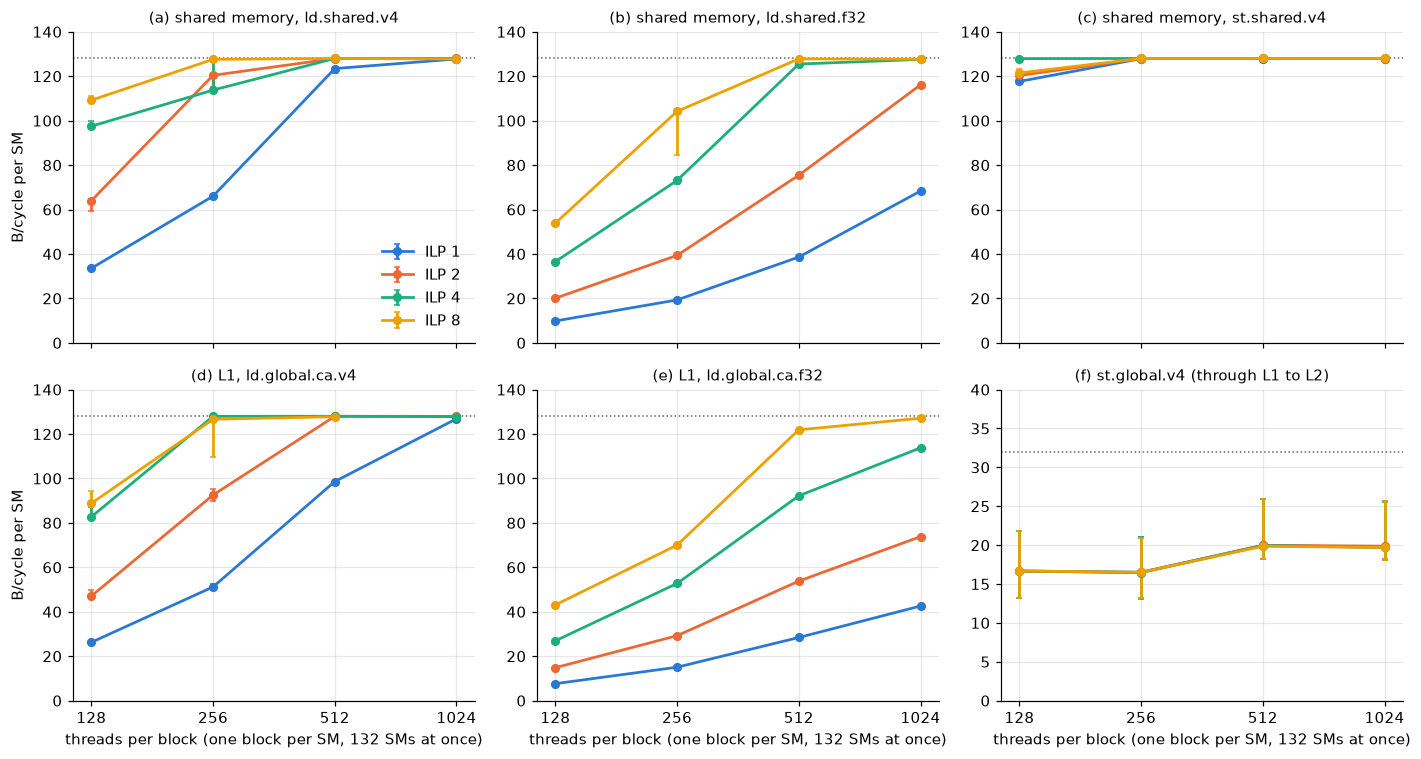

In [3]:
v = valid(k12)
v = v[(v.iters == 8192) & (v.pattern == "stride") & (v.placement == "all_sms")]
panels = [("smem", "ld", 16, "(a) shared memory, ld.shared.v4"), ("smem", "ld", 4, "(b) shared memory, ld.shared.f32"),
          ("smem", "st", 16, "(c) shared memory, st.shared.v4"), ("l1", "ld", 16, "(d) L1, ld.global.ca.v4"),
          ("l1", "ld", 4, "(e) L1, ld.global.ca.f32"), ("l1", "st", 16, "(f) st.global.v4 (through L1 to L2)")]
fig, axs = plt.subplots(2, 3, figsize=(13, 7), sharex=True)
for ax, (lev, op, w, title) in zip(axs.flat, panels):
    d = v[(v.level == lev) & (v.op == op) & (v.width_bytes == w)]
    for j, ilp in enumerate([1, 2, 4, 8]):
        g = d[d.ilp == ilp].groupby("threads").bpc_per_sm
        if g.ngroups == 0: continue
        m = g.median()
        ax.errorbar(m.index, m.values, yerr=[m - g.quantile(0.05), g.quantile(0.95) - m], color=C[j], marker="o",
                    capsize=2, label=f"ILP {ilp}")
    ax.set_title(title, fontsize=10); ax.set_xscale("log", base=2); ax.set_xticks([128, 256, 512, 1024], ["128", "256", "512", "1024"])
    ax.set_ylim(0, 140 if not (lev == "l1" and op == "st") else 40)
    ax.axhline(128 if not (lev == "l1" and op == "st") else 32, color="0.4", ls=":", lw=1)
for ax in axs[1]: ax.set_xlabel("threads per block (one block per SM, 132 SMs at once)")
for ax in axs[:, 0]: ax.set_ylabel("B/cycle per SM")
axs[0, 0].legend(loc="lower right")
fig.tight_layout(); plt.show()

**Best configuration per access type** (8192 steps): one block alone versus 132 SMs at once. The TB/s column multiplies by 132 SMs and by the SM clock measured by the blocks. The second table holds the hardware counters of one profiled launch per type (1024 threads, ILP 4, one block).

In [4]:
def best(lev, op, w, pl):
    d = valid(k12); d = d[(d.level == lev) & (d.op == op) & (d.width_bytes == w) & (d.iters == 8192) & (d.pattern == "stride") & (d.placement == pl)]
    m = d.groupby(["threads", "ilp"]).bpc_per_sm.median(); t, i = m.idxmax(); s = d[(d.threads == t) & (d.ilp == i)].bpc_per_sm
    return {"best config": f"{t} thr, ILP {i}", "median B/cycle/SM": round(s.median(), 2), "p5": round(s.quantile(.05), 2), "p95": round(s.quantile(.95), 2),
            "min over SMs": round(s.min(), 2), "TB/s for 132 SMs": round(s.median() * SMS * (d.cycles / d.ns).median() / 1e3, 2)}
rows = {f"{lev} {op} {w} B, {pl}": best(lev, op, w, pl) for lev, op, w in [("smem", "ld", 16), ("smem", "ld", 4), ("smem", "st", 16), ("smem", "st", 4),
        ("l1", "ld", 16), ("l1", "ld", 4), ("l1", "st", 16), ("l1", "st", 4)] for pl in ["single", "all_sms"]}
display(pd.DataFrame(rows).T)
n = n12[["level", "op", "width_bytes", "bpc_per_sm", "l1tex__data_bank_conflicts_pipe_lsu_mem_shared_op_ld.sum", "l1tex__data_bank_conflicts_pipe_lsu_mem_shared_op_st.sum",
         "l1tex__data_pipe_lsu_wavefronts_mem_shared_op_ld.sum", "l1tex__data_pipe_lsu_wavefronts_mem_shared_op_st.sum", "smsp__inst_executed_op_shared_ld.sum",
         "smsp__inst_executed_op_shared_st.sum", "l1tex__t_sector_pipe_lsu_mem_global_op_ld_hit_rate.pct", "lts__t_sectors_op_read.sum", "launch__shared_mem_config_size"]]
n.columns = ["level", "op", "width B", "B/cycle/SM", "smem ld bank conflicts", "smem st bank conflicts", "smem ld wavefronts", "smem st wavefronts",
             "smem ld instr", "smem st instr", "L1 hit rate %", "L2 read sectors", "smem carveout B"]
display(n.set_index(["level", "op", "width B"]))

,best config,median B/cycle/SM,p5,p95,min over SMs,TB/s for 132 SMs
"smem ld 16 B, single","512 thr, ILP 8",127.99,127.99,127.99,127.99,27.61
"smem ld 16 B, all_sms","512 thr, ILP 8",127.99,126.51,127.99,126.02,27.48
"smem ld 4 B, single","512 thr, ILP 8",127.79,127.78,127.83,127.77,27.56
"smem ld 4 B, all_sms","512 thr, ILP 8",127.8,127.77,127.82,127.75,27.37
"smem st 16 B, single","1024 thr, ILP 8",128.0,128.0,128.0,128.0,27.49
"smem st 16 B, all_sms","1024 thr, ILP 8",128.0,127.99,128.0,127.99,27.47
"smem st 4 B, single","256 thr, ILP 8",127.94,127.94,127.94,127.94,27.48
"smem st 4 B, all_sms","512 thr, ILP 4",127.93,127.92,127.94,127.92,27.18
"l1 ld 16 B, single","512 thr, ILP 4",127.99,127.98,128.0,127.98,27.61
"l1 ld 16 B, all_sms","512 thr, ILP 4",128.0,127.45,128.02,124.11,27.49


B/cycle/SM  smem ld bank conflicts  smem st bank conflicts  smem ld wavefronts  smem st wavefronts  smem ld instr  smem st instr  L1 hit rate %  L2 read sectors  smem carveout B
level op width B                                                                                                                                                                                   
smem  ld 16         127.8397                       0                       0             2097152                   0         524288              0           0.00            10144           135168
         4          127.5065                       0                       0              524288                   0         524288              0           0.00             3204           135168
      st 16         127.9814                       0                       0                   0             2097152              0         524288           0.00             2185           135168
         4          127.7116                       0                       0                   0              524288              0         524288           0.00             2073           135168
l1    ld 16         127.8102                       0                       0                   0                   0              0              0          99.98             8340             8192
         4          113.6279                       0                       0                   0                   0              0              0          99.98             3216             8192

**Figure 2 — every SM.** Median B/cycle of each SM (1024 threads, ILP 4, 16-B accesses, 132 SMs at once), coloured by L2 partition. Note the very different y-ranges: loads vary by less than 0.3 B/cycle between SMs, stores by 18–26 B/cycle.

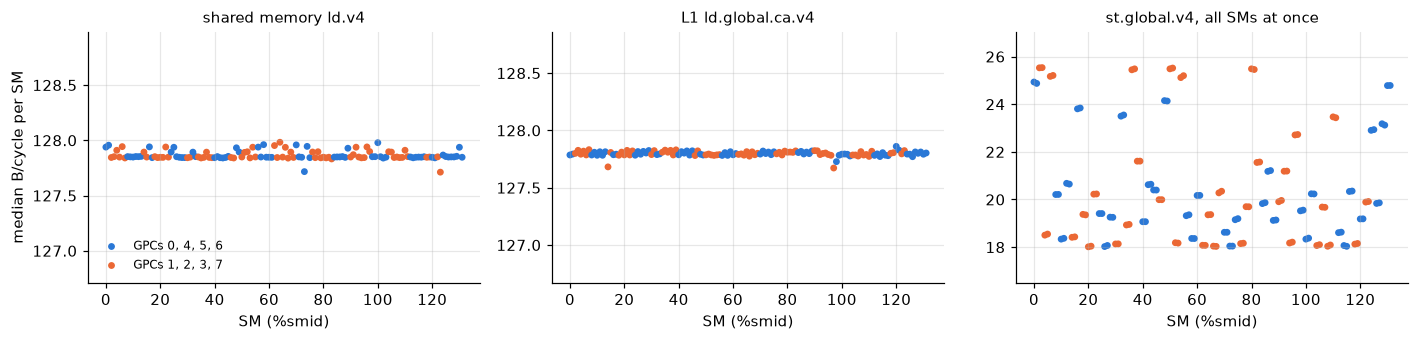

In [5]:
d = valid(k12)
d = d[(d.placement == "all_sms") & (d.iters == 8192) & (d.pattern == "stride") & (d.threads == 1024) & (d.ilp == 4) & (d.width_bytes == 16)]
gmap = pd.read_csv("../03__sm_gpc_topology/results/03__sm_gpc_topology__map.csv"); gmap = gmap[gmap.run_id == gmap.run_id.max()].set_index("smid").gpc
fig, axs = plt.subplots(1, 3, figsize=(13, 3.2), sharex=True)
for ax, (lev, op, title) in zip(axs, [("smem", "ld", "shared memory ld.v4"), ("l1", "ld", "L1 ld.global.ca.v4"), ("l1", "st", "st.global.v4, all SMs at once")]):
    m = d[(d.level == lev) & (d.op == op)].groupby("smid").bpc_per_sm.median()
    ax.scatter(m.index, m.values, s=12, c=[C[GPC_PART[gmap[s]]] for s in m.index])
    ax.set_title(title, fontsize=10); ax.set_xlabel("SM (%smid)")
    lo, hi = m.min(), m.max(); ax.set_ylim(lo - max(1, 0.2 * (hi - lo)), hi + max(1, 0.2 * (hi - lo)))
axs[0].set_ylabel("median B/cycle per SM")
axs[0].scatter([], [], c=C[0], s=12, label="GPCs 0, 4, 5, 6"); axs[0].scatter([], [], c=C[1], s=12, label="GPCs 1, 2, 3, 7"); axs[0].legend(loc="lower left", fontsize=8)
fig.tight_layout(); plt.show()

### 2. Where each L2 line lives (K3 labelling)

The per-access latencies split cleanly into near and far hits in both directions. The two directions are complementary for every line, so each line gets an unambiguous home. Probing one chunk from the first SM of every GPC reproduces the same labels, which confirms the two groups of four GPCs. The last lines below give the granularity of the home assignment.

786432 lines of 128 B labelled; home 0: 393216, home 1: 393216, ambiguous: 0; near/far threshold 355 cycles


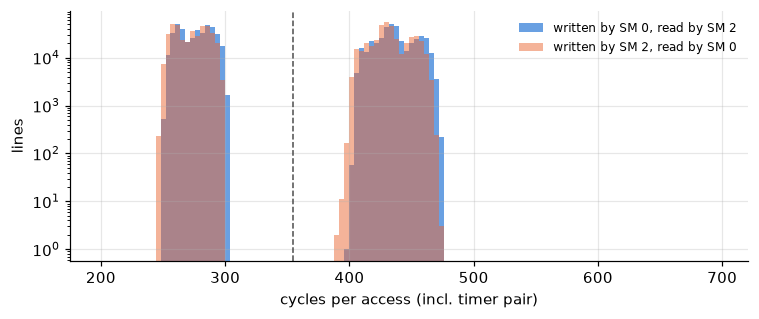

chunk 0 probed from the first SM of every GPC — % of lines whose near/far class matches the label: {'G0': np.float64(100.0), 'G1': np.float64(100.0), 'G2': np.float64(100.0), 'G3': np.float64(100.0), 'G4': np.float64(100.0), 'G5': np.float64(100.0), 'G6': np.float64(100.0), 'G7': np.float64(100.0)}
  units of    512 B whose lines have both homes: 0 of 196608
  units of   4096 B whose lines have both homes: 0 of 24576
  units of   8192 B whose lines have both homes: 12288 of 12288
  units of  16384 B whose lines have both homes: 6144 of 6144
  units of  65536 B whose lines have both homes: 1536 of 1536


In [6]:
h = home
print(f"{len(h)} lines of 128 B labelled; home 0: {(h.home == 0).sum()}, home 1: {(h.home == 1).sum()}, ambiguous: {(h.home < 0).sum()}; "
      f"near/far threshold {h.thr_cycles.iloc[0]:.0f} cycles")
fig, ax = plt.subplots(figsize=(7, 3))
bins = np.arange(200, 700, 4)
ax.hist(h.cycles_b.clip(upper=699), bins=bins, color=C[0], alpha=0.7, label="written by SM 0, read by SM 2")
ax.hist(h.cycles_a.clip(upper=699), bins=bins, color=C[1], alpha=0.5, label="written by SM 2, read by SM 0")
ax.axvline(h.thr_cycles.iloc[0], color="0.3", ls="--", lw=1); ax.set_yscale("log"); ax.set_xlabel("cycles per access (incl. timer pair)"); ax.set_ylabel("lines")
ax.legend(fontsize=8); fig.tight_layout(); plt.show()
c0 = h[h.cycles_g0.notna()]
agree = {f"G{g}": 100 * ((c0[f"cycles_g{g}"] > h.thr_cycles.iloc[0]) == (c0.home != GPC_PART[g])).mean() for g in range(8)}
print("chunk 0 probed from the first SM of every GPC — % of lines whose near/far class matches the label:", {k: round(x, 3) for k, x in agree.items()})
off = h.line_offset.values; hm = h.home.values
for unit in [512, 4096, 8192, 16384, 65536]:
    k = unit // 128; u = hm[: len(hm) // k * k].reshape(-1, k)
    print(f"  units of {unit:6d} B whose lines have both homes: {(u.min(1) != u.max(1)).sum()} of {len(u)}")

### 3. L2 bandwidth versus footprint (K3, K5)

**Figure 3.** Steady-state GPU-wide rate versus footprint: loads for the three variants, plus stores and a 50/50 load/store mix over all lines ("mixed"). 2 × 132 blocks × 1024 threads, ILP 4, `.cg`; median and p5–p95 of 10 launches. The right axis converts to B/cycle per SM at the SM clock measured during the runs.

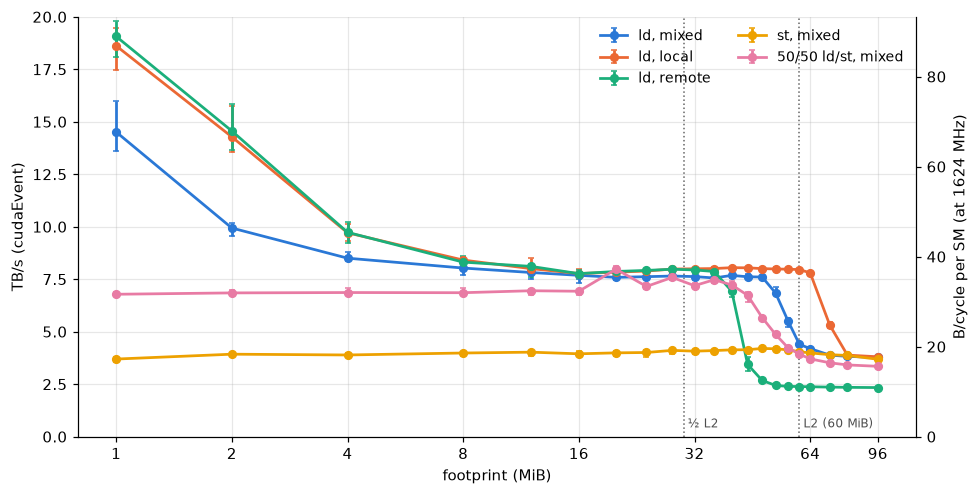

MiB             1      2     4     8     12    16    20    24    28    32  ...    40    44    48    52    56    60    64    72    80    96
op  variant                                                                ...                                                            
ld  mixed    14.51   9.94  8.50  8.03  7.82  7.68  7.59  7.62  7.65  7.63  ...  7.68  7.62  7.60  6.85  5.53  4.40  4.19  3.88  3.82  3.77
    local    18.62  14.28  9.71  8.41  8.00  7.77  7.84  7.89  7.98  8.00  ...  8.05  8.04  8.01  7.99  7.98  7.96  7.80  5.31  3.88  3.80
    remote   19.06  14.56  9.73  8.31  8.11  7.76  7.87  7.92  7.97  7.94  ...  6.93  3.44  2.68  2.44  2.39  2.39  2.38  2.36  2.35  2.34
st  mixed     3.70   3.93  3.89  3.98  4.02  3.95  3.99  4.01  4.11  4.07  ...  4.13  4.14  4.20  4.18  4.14  4.05  3.99  3.90  3.87  3.69
mix mixed     6.78   6.85  6.86  6.86  6.95  6.93  7.98  7.15  7.59  7.19  ...  7.23  6.73  5.67  4.87  4.24  3.93  3.70  3.52  3.42  3.35

[5 rows x 21 columns]

In [7]:
v = valid(l2)
s = v[(v["pass"] == 0) & (v.blocks == 2 * SMS) & (v.ilp == 4) & (v.cache_op == "cg")]
mhz = (l2b.cycles / l2b.ns * 1e3)[l2b.bytes > 0].median()
fig, ax = plt.subplots(figsize=(9, 4.6))
for j, (op, var, lab) in enumerate([("ld", "mixed", "ld, mixed"), ("ld", "local", "ld, local"), ("ld", "remote", "ld, remote"),
                                    ("st", "mixed", "st, mixed"), ("mix", "mixed", "50/50 ld/st, mixed")]):
    g = s[(s.op == op) & (s.variant == var)].groupby("footprint_bytes").tbps
    m = g.median(); x = m.index / 2**20
    ax.errorbar(x, m.values, yerr=[m - g.quantile(.05), g.quantile(.95) - m], color=C[j], marker="o", capsize=2, label=lab)
for f, t in [(30, "½ L2"), (60, "L2 (60 MiB)")]:
    ax.axvline(f, color="0.4", ls=":", lw=1); ax.text(f, 0.3, " " + t, fontsize=8, color="0.3", va="bottom")
ax.set_xscale("log", base=2); ax.set_xticks([1, 2, 4, 8, 16, 32, 64, 96], ["1", "2", "4", "8", "16", "32", "64", "96"])
ax.set_xlabel("footprint (MiB)"); ax.set_ylabel("TB/s (cudaEvent)"); ax.set_ylim(0, 20)
sec = ax.secondary_yaxis("right", functions=(lambda t: t * 1e12 / (mhz * 1e6) / SMS, lambda b: b * SMS * mhz * 1e6 / 1e12))
sec.set_ylabel(f"B/cycle per SM (at {mhz:.0f} MHz)")
ax.legend(loc="upper right", ncol=2, fontsize=9); fig.tight_layout(); plt.show()
t = s[s.op.isin(["ld", "st", "mix"])].groupby(["footprint_bytes", "op", "variant"]).tbps.median().unstack(["op", "variant"])
t.index = (t.index / 2**20).astype(int); t.index.name = "MiB"
display(t[[c for c in [("ld", "mixed"), ("ld", "local"), ("ld", "remote"), ("st", "mixed"), ("mix", "mixed")] if c in t.columns]].round(2).T)

**Variations at 16 MiB.** Thread and ILP choices, the list mechanism, cache operators and stores (median TB/s, p5–p95, chip-wide B/cycle).

In [8]:
v = valid(l2)
o = v[(v["pass"] == 0) & (v.footprint_bytes == 16 << 20)]
def row(q):
    g = o.query(q); return pd.Series({"TB/s": g.tbps.median(), "p5": g.tbps.quantile(.05), "p95": g.tbps.quantile(.95), "B/cycle chip": g.bpc_chip.median(), "launches": len(g)})
cases = {
    "mixed, list-free (2×1024 thr, ILP 4)": 'variant=="mixed" & op=="ld" & cache_op=="cg" & blocks==264 & ilp==4',
    "mixed, identity list through smem": 'variant=="mixed_list"', "mixed, plain grid-stride kernel": 'variant=="mixed_direct"',
    **{f"mixed, 2×1024 thr, ILP {i}": f'variant=="mixed" & op=="ld" & cache_op=="cg" & blocks==264 & ilp=={i}' for i in [1, 2]},
    **{f"mixed, 1×1024 thr, ILP {i}": f'variant=="mixed" & op=="ld" & cache_op=="cg" & blocks==132 & ilp=={i}' for i in [1, 2, 4, 8]},
    **{f"{var}, ld.global.{c}": f'variant=="{var}" & op=="ld" & cache_op=="{c}" & blocks==264' for c in ["cg", "cs", "lu", "cv"] for var in ["mixed", "local", "remote"]},
    **{f"{var}, {op}": f'variant=="{var}" & op=="{op}" & blocks==264' for op in ["st", "mix"] for var in ["mixed", "local", "remote"]},
}
display(pd.DataFrame({k: row(q) for k, q in cases.items()}).T.round(2))

,TB/s,p5,p95,B/cycle chip,launches
"mixed, list-free (2×1024 thr, ILP 4)",7.68,7.33,7.84,4740.78,20.0
"mixed, identity list through smem",7.60,7.46,7.80,4674.17,10.0
"mixed, plain grid-stride kernel",7.25,7.17,7.33,4450.81,10.0
"mixed, 2×1024 thr, ILP 1",7.43,7.23,7.67,4586.31,10.0
"mixed, 2×1024 thr, ILP 2",7.60,7.38,7.76,4671.84,10.0
"mixed, 1×1024 thr, ILP 1",7.18,7.00,7.22,4414.47,10.0
"mixed, 1×1024 thr, ILP 2",7.31,7.08,7.50,4511.17,10.0
"mixed, 1×1024 thr, ILP 4",7.54,7.33,7.75,4630.92,20.0
"mixed, 1×1024 thr, ILP 8",7.44,7.25,7.64,4580.71,10.0
"mixed, ld.global.cg",7.60,7.24,7.83,4687.62,40.0


**Hardware counters** (Nsight Compute, one profiled launch per configuration after the same warm-up). *Link sectors* are L2 sector accesses that arrived over the link between the partitions. The first row is a launch in which every block exits at once: what the profiler itself adds to every measurement. It is subtracted in the "per payload sector" column (1.0 = every byte crossed the link once). Hit rates of the short first-pass kernels (pass 1/2) include the profiler's own writes and are not representative.

In [9]:
n = nl2.copy()
keep = {"lts__t_sectors_srcunit_ltcfabric.sum": "link sectors", "lts__t_sectors_op_read.sum": "L2 read sectors", "lts__t_sectors_op_write.sum": "L2 write sectors",
        "lts__t_sector_hit_rate.pct": "L2 hit %", "dram__bytes_read.sum": "HBM read B", "dram__bytes_write.sum": "HBM write B",
        "lts__t_bytes.sum.per_second": "L2 B/s", "gpu__time_duration.sum": "ns"}
t = n[["variant", "op", "cache_op", "footprint_bytes", "pass", "reader_mask", "bytes"] + list(keep)].rename(columns=keep)
for c in keep.values(): t[c] = t[c].astype(float)
base = t.iloc[0]   # every block exits at once: what the profiler itself adds
t["MiB"] = (t.footprint_bytes / 2**20).astype(int)
t["link sectors − baseline, per payload sector"] = ((t["link sectors"] - base["link sectors"]) / (t.bytes / 32)).where(t.bytes > 0)
t["L2 TB/s"] = t["L2 B/s"] / 1e12
t["L2 read sectors per payload sector"] = (t["L2 read sectors"] / (t.bytes / 32)).where((t.bytes > 0) & (t.op == "ld"))
show = ["variant", "op", "cache_op", "MiB", "pass", "reader_mask", "link sectors", "link sectors − baseline, per payload sector",
        "L2 read sectors per payload sector", "L2 read sectors",
        "L2 write sectors", "L2 hit %", "HBM read B", "L2 TB/s", "ns"]
t.loc[0, "variant"] = "(empty kernel)"
display(t[show].round(3))

,variant,op,cache_op,MiB,pass,reader_mask,link sectors,"link sectors − baseline, per payload sector",L2 read sectors per payload sector,L2 read sectors,L2 write sectors,L2 hit %,HBM read B,L2 TB/s,ns
0,(empty kernel),ld,cg,16,0,0,369348.0,NaN,NaN,3590.0,1066530.0,99.88,1.920000e+04,3.605,9760.0
1,mixed,ld,cg,1,0,3,437485.0,0.000,0.456,122292890.0,1271457.0,111.88,4.787200e+04,7.359,537408.0
2,local,ld,cg,1,0,3,436561.0,0.000,0.350,93879078.0,1273257.0,100.27,4.633600e+04,6.837,445472.0
3,remote,ld,cg,1,0,3,437229.0,0.000,0.350,93863060.0,1273832.0,101.94,2.457600e+04,6.753,450976.0
4,mixed,ld,cg,4,0,3,452174.0,0.000,0.867,232456941.0,1271898.0,102.73,5.534720e+05,7.812,957536.0
5,local,ld,cg,4,0,3,436315.0,0.000,0.753,201854546.0,1273827.0,102.38,2.455040e+05,7.634,851616.0
6,remote,ld,cg,4,0,3,444656.0,0.000,0.750,201033427.0,1273483.0,105.95,2.017280e+05,7.710,839776.0
7,mixed,ld,cg,16,0,3,577511.0,0.001,0.999,267976058.0,1274017.0,100.00,6.356480e+06,7.811,1103136.0
8,local,ld,cg,16,0,3,440275.0,0.000,0.997,267499282.0,1273548.0,99.92,4.152320e+06,7.681,1119808.0
9,remote,ld,cg,16,0,3,584916.0,0.001,0.995,266895072.0,1273391.0,100.19,4.830208e+06,7.855,1092576.0


**Figure 4 — L2 read rate versus active SMs** (1 block × 1024 threads per SM, ILP 4, 16 MiB, mixed; the scheduler chooses the SMs, spread over all GPCs).

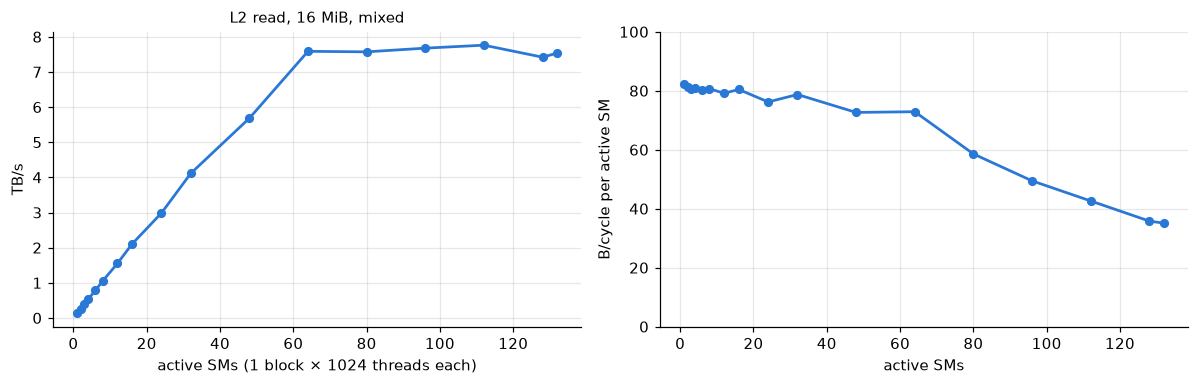

B/cycle per active SM: {1: 82.4, 2: 81.1, 3: 80.7, 4: 81.1, 6: 80.2, 8: 80.7, 12: 79.2, 16: 80.4, 24: 76.2, 32: 78.7, 48: 72.7, 64: 72.9, 80: 58.6, 96: 49.4, 112: 42.6, 128: 35.8, 132: 35.1}


In [10]:
v = valid(l2)
a = v[(v["pass"] == 0) & (v.variant == "mixed") & (v.op == "ld") & (v.cache_op == "cg") & (v.ilp == 4) & (v.threads == 1024) & (v.blocks <= SMS) & (v.footprint_bytes == 16 << 20)]
g = a.groupby("blocks"); m = g.tbps.median()
per = g.bpc_chip.median() / m.index
fig, axs = plt.subplots(1, 2, figsize=(11, 3.6))
axs[0].plot(m.index, m.values, "o-", color=C[0]); axs[0].set_xlabel("active SMs (1 block × 1024 threads each)"); axs[0].set_ylabel("TB/s"); axs[0].set_title("L2 read, 16 MiB, mixed", fontsize=10)
axs[1].plot(per.index, per.values, "o-", color=C[0]); axs[1].set_xlabel("active SMs"); axs[1].set_ylabel("B/cycle per active SM"); axs[1].set_ylim(0, 100)
fig.tight_layout(); plt.show()
print("B/cycle per active SM:", per.round(1).to_dict())

### 4. The link between the L2 partitions

**Figure 5.** Only the blocks on SMs of the chosen GPCs work: G1, G1–G2, G1–G3, partition 1 (○); G4, G4–G5, G4–G6, partition 0 (□); and both partitions (◆).
- Left: steady-state stores to lines homed in the writers' own partition (local) or in the other one (remote), and local loads. Stores leave no copy, so every remote store crosses the link on every pass.
- Right: the first-pass test (lines that exist only at home, 512 threads per SM), median B/cycle per reading SM, from the block timers.

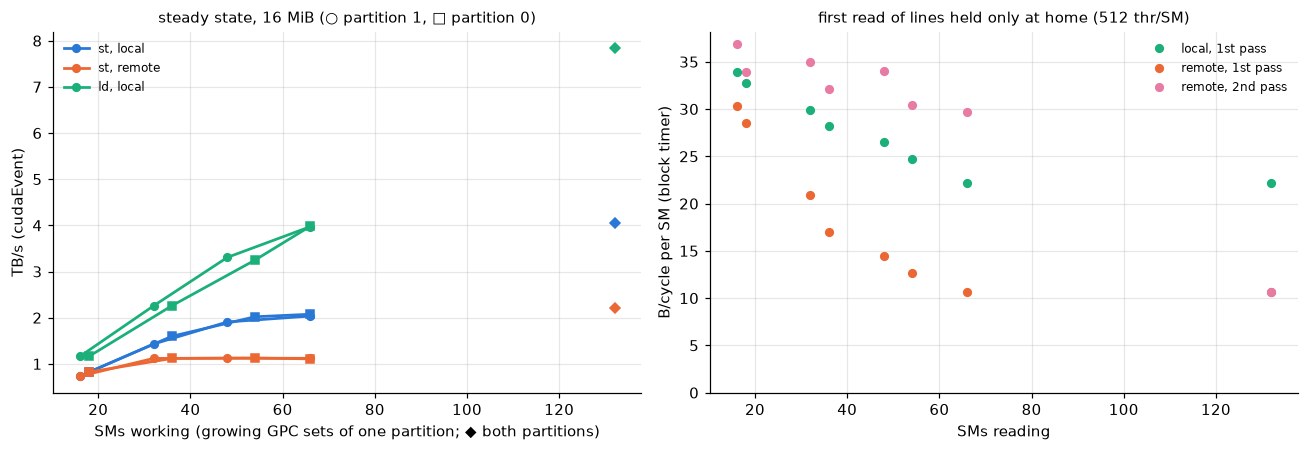

,"(ld, local)","(st, local)","(st, remote)","1st-pass ld local, pass 1: B/cycle/SM","1st-pass ld local, pass 2: B/cycle/SM","1st-pass ld remote, pass 1: B/cycle/SM","1st-pass ld remote, pass 2: B/cycle/SM"
G1 (16 SMs),1.16,0.73,0.73,34.0,38.0,30.4,36.9
G1–G2 (32 SMs),2.26,1.43,1.12,29.9,35.6,20.9,34.9
G1–G3 (48 SMs),3.31,1.91,1.12,26.5,33.4,14.4,34.0
G4 (18 SMs),1.16,0.82,0.82,32.7,34.9,28.6,33.9
G4–G5 (36 SMs),2.26,1.60,1.12,28.2,32.6,17.0,32.1
G4–G6 (54 SMs),3.25,2.02,1.13,24.7,30.5,12.7,30.4
partition 0 (66 SMs),3.98,2.07,1.11,22.5,30.1,10.6,29.5
partition 1 (66 SMs),3.97,2.04,1.12,22.0,30.1,10.6,29.9
both (132 SMs),7.84,4.06,2.22,22.2,28.9,10.6,10.7


In [11]:
v = valid(lk)
names = {0x02: "G1", 0x06: "G1–G2", 0x0E: "G1–G3", 0x8E: "partition 1", 0x10: "G4", 0x30: "G4–G5", 0x70: "G4–G6", 0x71: "partition 0", 0xFF: "both"}
gm = pd.read_csv("../03__sm_gpc_topology/results/03__sm_gpc_topology__map.csv"); gm = gm[gm.run_id == gm.run_id.max()]
nsm = {m: int(sum(((m >> g) & 1) for g in gm.gpc)) for m in names}
v = v.assign(sms=v.reader_gpc_mask.map(nsm), part=v.reader_gpc_mask.map(lambda m: "both" if m == 0xFF else ("1" if m & 0x8E == m else "0")))
st = v[v["pass"] == 0]; fp = v[v["pass"] > 0]
fig, axs = plt.subplots(1, 2, figsize=(12, 4.2))
for j, (op, var, lab) in enumerate([("st", "local", "st, local"), ("st", "remote", "st, remote"), ("ld", "local", "ld, local")]):
    for mk, p in [("o", "1"), ("s", "0"), ("D", "both")]:
        d = st[(st.op == op) & (st.variant == var) & (st.part == p)].groupby("sms").tbps.median()
        axs[0].plot(d.index, d.values, marker=mk, color=C[j], ls="-" if p != "both" else "none", label=lab if p == "1" else None)
axs[0].set_xlabel("SMs working (growing GPC sets of one partition; ◆ both partitions)"); axs[0].set_ylabel("TB/s (cudaEvent)")
axs[0].set_title("steady state, 16 MiB (○ partition 1, □ partition 0)", fontsize=10); axs[0].legend(fontsize=8)
fb = lkb.merge(lk[["launch_idx", "reader_gpc_mask", "threads"]], on="launch_idx"); fb = fb[(fb.bytes > 0) & (fb["pass"] > 0) & fb.discard.isna()]
fb = fb.assign(bpc=fb.bytes / fb.cycles, sms=fb.reader_gpc_mask.map(nsm))
for j, (var, ps, lab) in enumerate([("local", 1, "local, 1st pass"), ("remote", 1, "remote, 1st pass"), ("remote", 2, "remote, 2nd pass")]):
    d = fb[(fb.variant == var) & (fb["pass"] == ps)].groupby("sms").bpc.median()
    axs[1].plot(d.index, d.values, "o", color=[C[2], C[1], C[4]][j], label=lab)
axs[1].set_xlabel("SMs reading"); axs[1].set_ylabel("B/cycle per SM (block timer)"); axs[1].set_ylim(0, None)
axs[1].set_title("first read of lines held only at home (512 thr/SM)", fontsize=10); axs[1].legend(fontsize=8)
fig.tight_layout(); plt.show()
t = st.groupby(["reader_gpc_mask", "op", "variant"]).tbps.median().unstack(["op", "variant"])
t.index = [f"{names[m]} ({nsm[m]} SMs)" for m in t.index]
t2 = fb.groupby(["reader_gpc_mask", "variant", "pass"]).bpc.median().unstack(["variant", "pass"]); t2.index = t.index
t2.columns = [f"1st-pass ld {a}, pass {b}: B/cycle/SM" for a, b in t2.columns]
display(pd.concat([t.round(2), t2.round(1)], axis=1))

**First-pass test with all SMs** (K3): the same measurement with both partitions reading at once and for several footprints and block sizes. With 2 × 1024 threads per SM every warp finishes its range in 1–2 steps, so those rows are dominated by start-up and latency.

In [12]:
v = valid(l2); fp = v[v["pass"] > 0]
b = l2b.merge(l2[["launch_idx", "threads", "blocks", "reader_mask"]], on="launch_idx"); b = b[(b["pass"] > 0) & (b.bytes > 0) & b.discard.isna()]
b = b.assign(bpc=b.bytes / b.cycles)
t = b.groupby(["threads", "reader_mask", "footprint_bytes", "variant", "pass"]).bpc.median().unstack(["variant", "pass"])
t.index = [f"{th} thr/SM, {'both partitions' if m == 3 else 'partition ' + str(m - 1) + ' only'}, {f >> 20} MiB" for th, m, f in t.index]
t.columns = [f"{a}, pass {p}" for a, p in t.columns]
print("first-pass test — median B/cycle per reading SM (block timers):")
display(t.round(1))
s = fp.groupby(["threads", "reader_mask", "footprint_bytes", "variant", "pass"]).tbps_span.median().unstack(["variant", "pass"])
s.index = t.index; s.columns = [f"{a}, pass {p}" for a, p in s.columns]
print("GPU-wide TB/s over the %globaltimer span of the reading blocks:")
display(s.round(2))

first-pass test — median B/cycle per reading SM (block timers):


,"local, pass 1","local, pass 2","remote, pass 1","remote, pass 2","mixed, pass 1","mixed, pass 2"
"256 thr/SM, partition 0 only, 48 MiB",16.7,23.9,10.3,23.8,NaN,NaN
"256 thr/SM, partition 1 only, 48 MiB",16.2,23.5,10.3,23.7,NaN,NaN
"256 thr/SM, both partitions, 8 MiB",25.0,25.0,10.5,24.9,16.5,22.2
"256 thr/SM, both partitions, 16 MiB",27.6,27.2,10.6,27.2,17.9,25.1
"256 thr/SM, both partitions, 24 MiB",27.7,27.9,10.0,21.1,17.0,23.2
"512 thr/SM, partition 0 only, 48 MiB",22.3,30.3,10.6,29.3,NaN,NaN
"512 thr/SM, partition 1 only, 48 MiB",22.0,29.6,10.6,29.9,NaN,NaN
"512 thr/SM, both partitions, 8 MiB",30.5,30.5,11.0,30.5,18.4,28.3
"512 thr/SM, both partitions, 16 MiB",35.9,34.2,11.1,35.6,19.4,32.1
"512 thr/SM, both partitions, 24 MiB",36.4,35.5,10.6,25.1,18.4,30.5


GPU-wide TB/s over the %globaltimer span of the reading blocks:


,"local, pass 1","local, pass 2","remote, pass 1","remote, pass 2","mixed, pass 1","mixed, pass 2"
"256 thr/SM, partition 0 only, 48 MiB",1.41,1.88,1.04,1.75,NaN,NaN
"256 thr/SM, partition 1 only, 48 MiB",1.43,1.77,1.03,1.90,NaN,NaN
"256 thr/SM, both partitions, 8 MiB",3.94,3.91,1.91,3.88,2.82,3.30
"256 thr/SM, both partitions, 16 MiB",4.37,4.66,1.91,4.54,3.24,4.02
"256 thr/SM, both partitions, 24 MiB",3.63,5.07,1.82,2.66,2.96,3.72
"512 thr/SM, partition 0 only, 48 MiB",2.09,2.63,1.10,2.54,NaN,NaN
"512 thr/SM, partition 1 only, 48 MiB",2.06,2.62,1.10,2.55,NaN,NaN
"512 thr/SM, both partitions, 8 MiB",4.13,4.10,1.81,4.19,2.93,3.91
"512 thr/SM, both partitions, 16 MiB",5.04,5.49,2.02,4.70,3.47,4.88
"512 thr/SM, both partitions, 24 MiB",5.37,5.87,2.02,3.96,3.43,4.60


### 5. HBM (K4, K5)

**Figure 6.** HBM read and write rate versus active SMs (1 block × 1024 threads per SM, ILP 4, 64 KiB in flight per SM; median of 5 launches). Dashed: the per-SM rate of the first 8 SMs extrapolated. Dotted, coloured: the full-grid rate. Dotted, black: the theoretical peak.

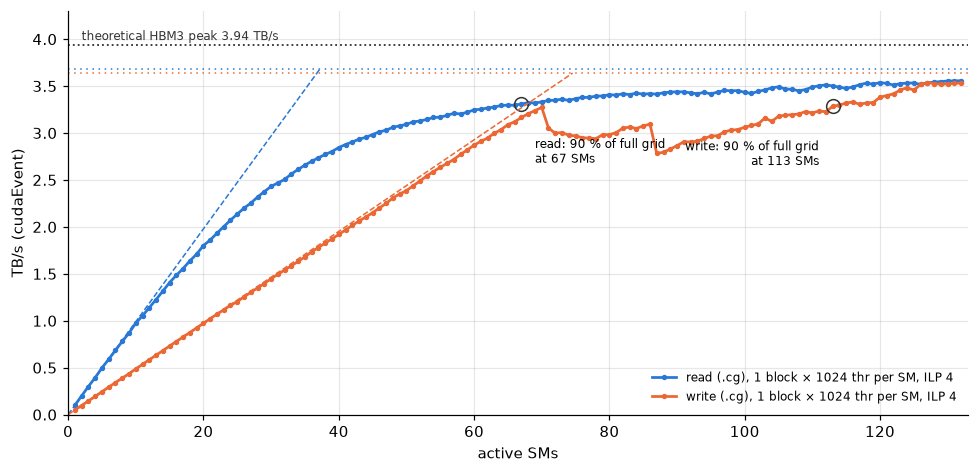

read: 98.9 GB/s per SM (60.8 B/cycle) for ≤ 8 SMs; 90 % of 3.68 TB/s reached at 67 SMs
write: 48.8 GB/s per SM (30.0 B/cycle) for ≤ 8 SMs; 90 % of 3.64 TB/s reached at 113 SMs


In [13]:
v = valid(dr)
sw = v[(v.threads == 1024) & (v.blocks <= SMS) & (v.ilp == 4) & (v.cache_op == "cg")]
fig, ax = plt.subplots(figsize=(9, 4.4))
knees = {}
for j, op in enumerate(["read", "write"]):
    g = sw[sw.op == op].groupby("blocks").tbps; m = g.median()
    ax.plot(m.index, m.values, ".-", color=C[j], label=f"{op} (.cg), 1 block × 1024 thr per SM, ILP 4")
    slope = (sw[(sw.op == op) & (sw.blocks <= 8)].gbps_per_sm).median() / 1e3
    full = v[(v.op == op) & (v.blocks == 4 * SMS) & (v.ilp == 4) & (v.cache_op == "cg")].tbps.median()
    knee = int(m[m >= 0.9 * full].index.min()); knees[op] = (slope, knee, full)
    ax.plot([0, full / slope], [0, full], color=C[j], ls="--", lw=1)
    ax.axhline(full, color=C[j], ls=(0, (1, 3)), lw=1)
    ax.plot([knee], [m[knee]], "o", ms=9, mfc="none", mec="0.2")
    ax.text(knee + 2 if knee < 100 else knee - 2, m[knee] - 0.35, f"{op}: 90 % of full grid\nat {knee} SMs", fontsize=8, va="top",
            ha="left" if knee < 100 else "right")
ax.axhline(PEAK_HBM, color="0.2", ls=":", lw=1.2); ax.text(2, PEAK_HBM + 0.05, "theoretical HBM3 peak 3.94 TB/s", fontsize=8, color="0.2")
ax.set_xlabel("active SMs"); ax.set_ylabel("TB/s (cudaEvent)"); ax.set_xlim(0, 133); ax.set_ylim(0, 4.3); ax.legend(loc="lower right", fontsize=8)
fig.tight_layout(); plt.show()
for op, (s, k, f) in knees.items():
    print(f"{op}: {s*1e3:.1f} GB/s per SM ({s*1e12/(sw.sm_mhz_blocks.median()*1e6):.1f} B/cycle) for ≤ 8 SMs; 90 % of {f:.2f} TB/s reached at {k} SMs")

**Full grid** (4 × 132 blocks × 1024 threads), every operation and cache operator, and the ncu counters of one launch each.

In [14]:
v = valid(dr)
fg = v[v.blocks == 4 * SMS]
t = fg.groupby(["op", "cache_op", "ilp"]).tbps.agg(["median", lambda x: x.quantile(.05), lambda x: x.quantile(.95), "count"])
t.columns = ["TB/s", "p5", "p95", "launches"]; t["% of 3.94 TB/s"] = 100 * t["TB/s"] / PEAK_HBM
display(t.round(3))
n = ndr[["op", "cache_op", "dram__bytes_read.sum", "dram__bytes_write.sum", "dram__bytes.sum.per_second", "dram__throughput.avg.pct_of_peak_sustained_elapsed",
         "lts__t_sectors_srcunit_ltcfabric.sum", "lts__d_sectors_fill_device.sum"]].copy()
n.columns = ["op", "cache_op", "HBM read B", "HBM write B", "HBM B/s (ncu)", "ncu % of its peak", "link sectors", "L2 fill sectors from HBM"]
n["link sectors / HBM sectors"] = n["link sectors"].astype(float) / ((n["HBM read B"].astype(float) + n["HBM write B"].astype(float)) / 32)
display(n.round(3))

TB/s     p5    p95  launches  % of 3.94 TB/s
op    cache_op ilp                                               
mix   cg       4    3.516  3.501  3.520        10          89.250
      cs       4    3.274  3.268  3.281        10          83.088
mix11 cg       4    3.397  3.389  3.408        10          86.211
      cs       4    3.309  3.290  3.320        10          83.984
read  cg       1    3.606  3.590  3.622        10          91.529
               2    3.671  3.659  3.678        10          93.164
               4    3.678  3.667  3.686        10          93.340
               8    3.633  3.617  3.649        10          92.208
      cs       4    3.679  3.664  3.692        10          93.366
write cg       4    3.638  3.621  3.659        10          92.346
      cs       4    3.669  3.636  3.691        10          93.118

,op,cache_op,HBM read B,HBM write B,HBM B/s (ncu),ncu % of its peak,link sectors,L2 fill sectors from HBM,link sectors / HBM sectors
0,read,cg,2147524352,2795008,3.691358e+12,91.76,33905474,67110178,0.505
1,write,cg,18944,2120655872,3.620777e+12,90.01,34316101,593,0.518
2,mix,cg,2172253184,423682048,3.551950e+12,88.30,41186572,67882921,0.508
3,mix11,cg,1074905088,1061884416,3.403572e+12,84.61,34321453,33590763,0.514
4,read,cs,2147494656,2764032,3.685585e+12,91.62,33903793,67109207,0.505
5,write,cs,17664,2120550656,3.641686e+12,90.53,34344052,585,0.518
6,mix,cs,2177948416,419325440,3.451031e+12,85.79,41212251,68060891,0.508
7,mix11,cs,1073791232,1058882048,3.332635e+12,82.85,34319591,33556003,0.515


### 6. Summary

**Figure 7.** GPU-wide bandwidth of each level (log scale), with B/cycle per SM. For SMEM and L1 the GPU-wide figure is 132 × the per-SM rate at the measured clock. The table holds the values (`results/05__bandwidth__summary.csv`).

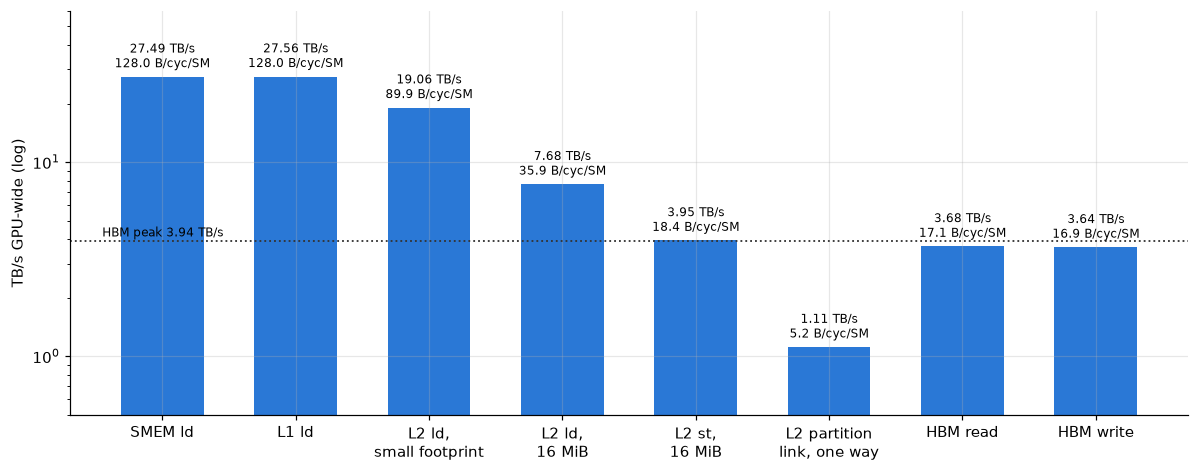

,median,p5,p95,unit,n,bpc_per_sm,tbps,config
level,,,,,,,,
smem_ld,127.9905,127.9903,127.9906,B/cycle/SM,10,127.9905,27.4889,"512 threads, ILP 8, 132 SMs at once; clock 162..."
smem_st,127.9950,127.9949,127.9951,B/cycle/SM,10,127.9950,27.6031,"1024 threads, ILP 8, 132 SMs at once; clock 16..."
l1_ld,127.9979,127.9954,128.0003,B/cycle/SM,10,127.9979,27.5600,"512 threads, ILP 4, 132 SMs at once; clock 163..."
l1_st_all_sms,19.9713,19.8807,20.1131,B/cycle/SM,10,19.9713,4.3063,"512 threads, ILP 2, 132 SMs at once; clock 163..."
l2_ld_mixed,7.6848,7.3318,7.8426,TB/s,20,35.9150,7.6848,"16 MiB, 2 x 132 x 1024 threads, ILP 4"
l2_ld_local,7.7701,7.5925,7.9850,TB/s,10,36.3993,7.7701,"16 MiB, 2 x 132 x 1024 threads, ILP 4"
l2_ld_remote,7.7645,7.5002,7.9340,TB/s,10,36.1976,7.7645,"16 MiB, 2 x 132 x 1024 threads, ILP 4"
l2_st_mixed,3.9457,3.8733,4.0993,TB/s,10,18.4062,3.9457,"16 MiB, 2 x 132 x 1024 threads, ILP 4"
l2_st_local,4.0594,4.0107,4.1479,TB/s,10,18.8301,4.0594,"16 MiB, 2 x 132 x 1024 threads, ILP 4"


In [15]:
import json
summ = pd.read_csv(f"{R}/05__bandwidth__summary.csv"); summ = summ[summ.run_id == summ.run_id.max()].set_index("level")
bars = [("smem_ld", "SMEM ld"), ("l1_ld", "L1 ld"), ("l2_ld_max", "L2 ld,\nsmall footprint"), ("l2_ld_mixed", "L2 ld,\n16 MiB"),
        ("l2_st_mixed", "L2 st,\n16 MiB"), ("l2_link_one_way", "L2 partition\nlink, one way"), ("dram_read", "HBM read"), ("dram_write", "HBM write")]
bars = [(k, n) for k, n in bars if k in summ.index]
fig, ax = plt.subplots(figsize=(11, 4.4))
x = np.arange(len(bars)); tb = [summ.loc[k, "tbps"] for k, _ in bars]
ax.bar(x, tb, width=0.62, color=C[0])
for i, (k, _) in enumerate(bars):
    ax.text(i, tb[i] * 1.12, f"{tb[i]:.2f} TB/s\n{summ.loc[k, 'bpc_per_sm']:.1f} B/cyc/SM", ha="center", fontsize=8)
ax.axhline(PEAK_HBM, color="0.2", ls=":", lw=1.2); ax.text(-0.45, PEAK_HBM * 1.05, "HBM peak 3.94 TB/s", fontsize=8, ha="left")
ax.set_yscale("log"); ax.set_ylim(0.5, 60); ax.set_xticks(x, [n for _, n in bars]); ax.set_ylabel("TB/s GPU-wide (log)")
fig.tight_layout(); plt.show()
display(summ[["median", "p5", "p95", "unit", "n", "bpc_per_sm", "tbps", "config"]])

## Insights

### The bandwidth ladder
At the locked 1635 MHz (GPU-wide figures in TB/s; per-SM figures in bytes per SM cycle):

| level, access | per SM | GPU-wide |
|---|---|---|
| shared memory, loads and stores, 4 or 16 B per thread | **128.0 B/cycle** | 27.5 TB/s |
| L1 hit, `ld.global.ca` 16 B (4 B: 127.1) | **128.0 B/cycle** | 27.6 TB/s |
| L2 read, steady state, 16 MiB, all SMs | 35.9 B/cycle (one SM alone: 81) | **7.7 TB/s** (local data 7.8–8.0) |
| L2 store, all SMs | 18.4 B/cycle (one SM alone: 32) | **4.0 TB/s** |
| link between the L2 partitions, per direction | — | **1.11 TB/s** (2.22 both ways) |
| HBM read / write / 5R+1W / 1R+1W | 17.1 B/cycle | **3.68 / 3.64 / 3.52 / 3.40 TB/s** (93 / 92 / 89 / 86 % of 3.94) |

Launch-to-launch variation is a few percent at most (p5–p95 in the tables).

### Shared memory and L1: one 128-byte data path
- **Both deliver exactly 128 B/cycle per SM**: loads and stores to shared memory, and L1 hits. Every one of the 132 SMs reaches it, also with all of them running at once.
- The counters show one 128-byte wavefront per 32-bit warp access and four per 16-byte access, with no bank conflicts. Shared memory and L1 therefore share a data path that moves one wavefront per cycle.
- **What it takes to saturate** (Figure 1):
  - 16-byte shared-memory accesses reach ≥ 120 B/cycle from 512 threads at ILP 1, or 256 threads at ILP 2.
  - L1 hits need about twice the bytes in flight for the same rate (128 B/cycle at 256 threads with ILP 4, 512 with ILP 2, or 1024 with ILP 1), consistent with their longer latency (32 versus 23 cycles).
  - 32-bit accesses need one load instruction per SM per cycle. They are bounded by instruction issue at low ILP (68 B/cycle at 1024 threads, ILP 1) and need ILP 4–8 with 512–1024 threads.
- Same-address repeated L1 loads at ILP 8 are merged by the compiler; that case was excluded (Figure 1).
- **Stores leave the SM at most at 32 B/cycle.** `st.global` goes through L1 to the L2: one SM alone stores 32.0 B/cycle at any width, thread count or ILP. With all 132 SMs storing at once the L2 limits the chip to ≈ 4.0–4.3 TB/s, and per SM this varies between 18 and 26 B/cycle (Figure 2).

### L2: 7.7 TB/s, limited per GPC and per partition link
- **Full-chip read rate.** 7.7 TB/s with all SMs and a 16 MiB footprint, 7.8–8.0 TB/s for partition-local data up to 64 MiB. That is ≈ 4950 B per L2 cycle at the 1557 MHz L2 clock, or 36 B per SM cycle.
  - The rate barely depends on ILP (7.2–7.6 TB/s for ILP 1–8) or on 1 versus 2 blocks per SM.
  - Plain grid-stride and list-driven kernels agree within 6 %.
- **Per SM and per GPC.**
  - One SM alone reads ≈ 81 B/cycle, and so does each of up to 16 SMs spread over the GPCs (Figure 4).
  - SMs of *one* GPC together never exceed **1.16 TB/s**, for 16 SMs (G1) as for 18 (G4). Two, three and four GPCs give 2.26, 3.3 and 4.0 TB/s (Figure 5).
  - So the port between a GPC and the L2 carries ≈ 1.16 TB/s ≈ 710 B per SM cycle. Below that, the chip-wide L2 limit of ≈ 7.7 TB/s binds, which is reached with ≈ 64 SMs spread over all GPCs.
- **Stores reach about half the read rate**: 4.0 TB/s, independent of footprint, even beyond the L2 capacity. The 50/50 mix reaches 6.9 TB/s.
- **Small footprints are not L2 bandwidth.** At 1–4 MiB the measured rate climbs to 19 TB/s. There, many SMs read the same lines at the same time, and the counters show that only 35–46 % (1 MiB) and 75–87 % (4 MiB) of the requested sectors reach the L2 tag lookup: requests to the same sectors are merged before the L2. From 16 MiB on, every requested sector is looked up once.
- **Capacity.** The plateau holds up to the footprint at which the data, including copies, no longer fits:

  | data | plateau holds up to | then |
  |---|---|---|
  | local (one copy per line) | 64 MiB | collapses between 64 and 72 MiB |
  | mixed | 48 MiB | drops from 52 MiB on |
  | remote (every line held twice) | 36 MiB | 6.9 TB/s at 40 MiB, 3.4 TB/s at 44 MiB |

  Beyond the capacity, remote data streams at only 2.35 TB/s, below the HBM rate: every miss also crosses the partition link (0.84 link sectors per payload sector at 48 MiB).

### The two L2 partitions and the link between them
- **Homes.** Every line has a home in one of the two partitions: exactly half of a buffer each. The assignment is constant within 4 KiB and changes inside every 8 KiB. All eight GPCs agree on it, in two groups of four ({G0, G4, G5, G6} and {G1, G2, G3, G7}).
- **Repeated reads never see the far partition.** Local, remote and mixed data stream at the same 7.7–7.8 TB/s, and the link carries no traffic beyond the profiler's own: every read leaves a copy in the reader's partition.
  - None of the load cache operators changes this. `.cv` behaves like `.cg`.
  - `.lu` and `.cs` give up the copies but also part of the L2 residency, so their data partly comes from HBM again.
  - `.cs` loads are additionally served partly by L1 (12–14 TB/s apparent at 16 MiB, half of the read sectors reaching L2), because unlike `.cg` they may hit in L1.
- **The link carries 1.11 TB/s per direction (2.22 TB/s both ways).** Three independent measurements agree:
  1. stores to lines homed in the other partition (stores never leave a copy, so every one crosses the link) saturate at 1.11–1.13 TB/s from two GPCs on, whichever partition writes;
  2. the first read of lines held only in the other partition saturates at 1.10 TB/s;
  3. with all SMs, remote stores reach exactly twice that.

  That is ≈ 715 B per L2 cycle in each direction: one seventh of the L2 read bandwidth, and less than one GPC's own port.
- **First reads per SM.** A partition's 66 SMs reading far data get ≈ 10.6 B/cycle each, against 22 B/cycle for near data in the same test. The second pass over the same lines runs at the near rate, since the copies now exist. When both partitions read 24 MiB from each other at once (48 MiB plus copies), the copies no longer fit and the second pass stays far.
- **HBM traffic crosses the link too.** Half of all HBM bytes (0.505 link sectors per HBM sector) belong to lines homed in the other partition. Reading HBM at 3.69 TB/s thus moves ≈ 0.93 TB/s over the link in each direction, 84 % of its capacity.

### HBM
- **Full-chip rates.** Reads reach 3.68 TB/s (93 % of the 3.94 TB/s peak computed from the interface), writes 3.64 TB/s, and mixes of reads and writes 3.40–3.52 TB/s. `.cs` and `.cg` behave the same.
  - The profiler reports the read kernel at 91.8 % of *its* peak, so it assumes ≈ 4.02 TB/s.
- **Per SM.**
  - With 64 KiB in flight, one SM reads ≈ 99 GB/s (61 B/cycle). Reads reach 90 % of the full-grid rate with 67 SMs.
  - Writes are limited per SM by the 32 B/cycle store path (49 GB/s = 30 B/cycle per SM) and need 113 SMs for 90 %.
  - The write curve has two downward steps, at 71 active SMs (−0.22 TB/s) and at 87 (−0.31 TB/s), after each of which it rises again (Figure 6). They are reproducible: the 5 launches of each point lie within ±0.03 TB/s. Which SMs the scheduler adds at those counts, and why that lowers the write rate, is not resolved here.
- **ILP** (1–8 at 2048 threads per SM) changes the full-grid read rate by < 2 %.

### Limitations
- The L2 far-read rate is a first-pass measurement (≈ 22 µs per pass for one partition at 512 threads per SM); its per-SM rates come from block timers.
- With 2 × 1024 threads per SM the first-pass kernels end after 1–2 steps per warp and measure start-up, not bandwidth. The tables show them for completeness.
- The profiler adds ≈ 1.1 M L2 write sectors and 0.37 M link sectors to every profiled kernel (empty-kernel row). This distorts the hit rates of the short profiled kernels, not the timed runs.
- The SM clock measured by the block timers ranged over 1597–1648 MHz (p5–p95). No launch was discarded.